# **Numpy Question & Answer**
**Note: First of all try Yourself then Google it for most Efficient Answer**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

###`Q-1:` Find the nearest element in the array for each of the given numbers (no loops).
```
Ex:-
numbers = [12 38 70] and array - [ 5 18 33 47 52 66 81].
Nearest elements are [18 33 66]
```
Hint: Read about this function `argmin()` and its `axis` parameter. Also try to make numbers as a column array.

In [2]:
#Code here
array = np.array([5, 18, 33, 47, 52, 66, 81])
numbers = np.array([12, 38, 70])

# numbers[:, None] makes it a column (3,1), array is (7,), so the gap matrix becomes (3,7)
gap = np.abs(numbers[:, None] - array)
print(gap)

# argmin with axis=1 gives the smallest gap place in every row
array[np.argmin(gap, axis=1)]

[[ 7  6 21 35 40 54 69]
 [33 20  5  9 14 28 43]
 [65 52 37 23 18  4 11]]


array([18, 33, 66])

###`Q-2:` Replace the numbers of the given array with this rule.
* multiples of both 2 and 7 -> -1
* multiples of only 2 or only 7 -> 0
* all other numbers stay the same

```
arr = np.arange(1, 21)

result-> [ 1  0  3  0  5  0  0  0  9  0 11  0 13 -1 15  0 17  0 19  0]
```
Hint: Read about `np.select()`

In [3]:
#Code here
arr = np.arange(1, 21)

by2 = arr % 2 == 0
by7 = arr % 7 == 0

# np.select checks the conditions one by one, the first True condition gives the value
# so the "both" condition must be written first
np.select([by2 & by7, by2 | by7], [-1, 0], default=arr)

array([ 1,  0,  3,  0,  5,  0,  0,  0,  9,  0, 11,  0, 13, -1, 15,  0, 17,
        0, 19,  0])

###`Q-3:` Use Fancy Indexing.
1. Make the anti-diagonal of the given 5x5 array 0 (positions (0,4), (1,3), (2,2), (3,1), (4,0)).
```
arr = np.arange(25).reshape(5, 5)
```

2. Using a given array make a 2D array as in below example, where every next row is shifted by one place to the left.
```
array = [1,2,3]
result array -> [[1 2 3]
                 [2 3 1]
                 [3 1 2]]
```
* The size of the result should depend on the length of the array.

Hint:
```
if a is an array
a = [2,4]
a[[[0,1],[1,0]]] will result in-> [[2 4]
                                   [4 2]]
```

In [4]:
#Code here
arr = np.arange(25).reshape(5, 5)

rows = np.arange(5)
cols = 4 - rows       # [4,3,2,1,0]
arr[rows, cols] = 0
arr

array([[ 0,  1,  2,  3,  0],
       [ 5,  6,  7,  0,  9],
       [10, 11,  0, 13, 14],
       [15,  0, 17, 18, 19],
       [ 0, 21, 22, 23, 24]])

In [5]:
array = np.array([1, 2, 3])
n = array.size

# row i should start from i, so index matrix is (i + j) % n
# example for n=3 -> [[0 1 2], [1 2 0], [2 0 1]]
index = (np.arange(n)[:, None] + np.arange(n)) % n
array[index]

array([[1, 2, 3],
       [2, 3, 1],
       [3, 1, 2]])

###`Q-4:` You are given a 2D array which is having some nan values. Your job is to fill the nan values of every column with the mean of that same column.
```
arr=np.array([[1,np.nan,3],
              [4,5,np.nan],
              [np.nan,8,9],
              [10,np.nan,12]])

result-> [[ 1.   6.5  3. ]
          [ 4.   5.   8. ]
          [ 5.   8.   9. ]
          [10.   6.5 12. ]]
```
Hint: `np.nanmean()` ignores the nan values while finding the mean. Use its `axis` parameter.

In [6]:
#Code here
arr = np.array([[1, np.nan, 3],
                [4, 5, np.nan],
                [np.nan, 8, 9],
                [10, np.nan, 12]])

# mean of each column without nan, shape is (3,)
col_mean = np.nanmean(arr, axis=0)
print(col_mean)

# col_mean is broadcasted on all rows, so every nan gets the mean of its own column
np.where(np.isnan(arr), col_mean, arr)

[5.  6.5 8. ]


array([[ 1. ,  6.5,  3. ],
       [ 4. ,  5. ,  8. ],
       [ 5. ,  8. ,  9. ],
       [10. ,  6.5, 12. ]])

### `Q-5:` Write a NumPy program

- to find the missing data in a given array. Return a boolean matrix.
- remove all the rows which have any missing value.
- print what percent of the total values are missing.
- also try to fill those missing values with 0. For that, you can use `np.nan_to_num(a, nan=0)`

```python
import numpy as np

np.array([[7, np.nan, 3, 8],
          [4, 6, 5, 2],
          [np.nan, 9, 1, np.nan],
          [3, 3, 8, 1],
          [2, np.nan, 6, 7]])
```

In [7]:
#Code here
arr = np.array([[7, np.nan, 3, 8],
                [4, 6, 5, 2],
                [np.nan, 9, 1, np.nan],
                [3, 3, 8, 1],
                [2, np.nan, 6, 7]])
missing = np.isnan(arr)
missing

array([[False,  True, False, False],
       [False, False, False, False],
       [ True, False, False,  True],
       [False, False, False, False],
       [False,  True, False, False]])

In [8]:
# any(axis=1) is True if the row has at least one nan, ~ reverses it
arr[~missing.any(axis=1)]

array([[4., 6., 5., 2.],
       [3., 3., 8., 1.]])

In [9]:
# mean of True/False gives the fraction of True values
print(missing.mean() * 100, "%")

20.0 %


In [10]:
np.nan_to_num(arr, nan=0)

array([[7., 0., 3., 8.],
       [4., 6., 5., 2.],
       [0., 9., 1., 0.],
       [3., 3., 8., 1.],
       [2., 0., 6., 7.]])

###`Q-6:` Construct the matrices using broadcasting (no loops).

1. Given two arrays, X and Y, construct the matrix C where `Cij = (xi - yj)^2`
```
x = np.array([1,2,3,4]).reshape((-1, 1))
y = np.array([2,5,7])
```

2. Given 4 points in 2D, construct the distance matrix D where `Dij` is the distance between point i and point j. Round the answer to 2 decimal places.
```
points = np.array([[0,0],[3,4],[6,8],[0,5]])
```
Hint: for the second part, think about making the points array as shape (4,1,2) and (1,4,2).

In [11]:
#Code here
x = np.array([1, 2, 3, 4]).reshape((-1, 1))
y = np.array([2, 5, 7])

# x is (4,1) and y is (3,), so x - y becomes (4,3)
c = (x - y) ** 2
print(c)
print(c.shape)

[[ 1 16 36]
 [ 0  9 25]
 [ 1  4 16]
 [ 4  1  9]]
(4, 3)


In [12]:
points = np.array([[0, 0], [3, 4], [6, 8], [0, 5]])

# (4,1,2) - (1,4,2) -> (4,4,2), here [i, j] has the difference between point i and point j
diff = points[:, None, :] - points[None, :, :]

# square, add the last axis (x and y), then root
d = np.sqrt((diff ** 2).sum(axis=2))
print(np.round(d, 2))

[[ 0.    5.   10.    5.  ]
 [ 5.    0.    5.    3.16]
 [10.    5.    0.    6.71]
 [ 5.    3.16  6.71  0.  ]]


###`Q-7:` Plot these three functions on the same graph with different colours and a legend.

$$\large sigmoid(x) = \frac{1}{1 + e^{-x}}$$

$$\large tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$$

$$\large relu(x) = max(0, x)$$

The range of x should be between -6 to 6.

**Note: These three are activation functions used in deep learning. Look at the graph and note down one difference between them in your notebook.**

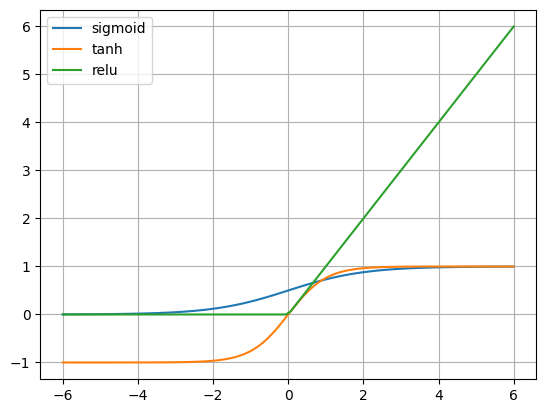

In [13]:
#Code here
x = np.linspace(-6, 6, 100)

sigmoid = 1 / (1 + np.exp(-x))
tanh = (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))
relu = np.maximum(0, x)    # maximum compares element by element

plt.plot(x, sigmoid, label="sigmoid")
plt.plot(x, tanh, label="tanh")
plt.plot(x, relu, label="relu")
plt.legend()
plt.grid()
plt.show()

**Difference:** sigmoid gives the output between 0 and 1, tanh gives the output between -1 and 1, but relu has no upper limit (it gives 0 for all negative numbers).

### `Q-8:` Plot the full circle of the below equation (upper half and lower half both).

$$\large (x - 1)^2 + (y - 2)^2 = 25$$

The range of x should be between -4 to 6. $x ∈ [-4, 6]$

Also mark the centre of the circle with a red dot, and make sure that the circle looks like a circle (not an oval).

Hint: solve the equation for y, you will get two values of y for every x.

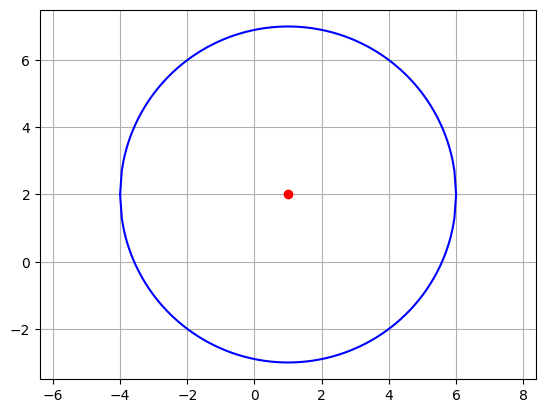

In [14]:
#Code here
x = np.linspace(-4, 6, 200)

# y = 2 + root(...) is the upper half and y = 2 - root(...) is the lower half
root = np.sqrt(25 - (x - 1) ** 2)
plt.plot(x, 2 + root, color="blue")
plt.plot(x, 2 - root, color="blue")

plt.plot(1, 2, "ro")      # centre
plt.axis("equal")         # same scale on both axes
plt.grid()
plt.show()

### `Q-9:` Write a program implement Broadcasting Rule to check if two arrays can be added or not. If they can be added, also return the shape of the result.
Given tuples of shapes.
```
shape of a- (3,2,2)
shape of b- (2,2)

check_broadcast(a, b) -> return (True, (3,2,2))
```
If they can not be broadcasted return `(False, None)`.

Rule: compare the shapes from the right side. Two numbers are okay if they are equal or any one of them is 1. If one shape is shorter, imagine 1s on its left side.

```
(5,1,4) and (3,1) -> (True, (5,3,4))
(4,3) and (4,)    -> (False, None)
```

In [15]:
#Code here
def check_broadcast(a, b):
    # make both shapes of same length by putting 1s on the left side
    n = max(len(a), len(b))
    a = (1,) * (n - len(a)) + a
    b = (1,) * (n - len(b)) + b

    result = []
    for i, j in zip(a, b):
        if i != j and i != 1 and j != 1:
            return False, None
        result.append(max(i, j))
    return True, tuple(result)

print(check_broadcast((3, 2, 2), (2, 2)))
print(check_broadcast((5, 1, 4), (3, 1)))
print(check_broadcast((4, 3), (4,)))

(True, (3, 2, 2))
(True, (5, 3, 4))
(False, None)


In [16]:
# checking our answer with numpy
print(np.broadcast_shapes((5, 1, 4), (3, 1)))

(5, 3, 4)


## Bonus Questions

###`Q-10:` In every row of the given 2D array, find the element which is nearest to the mean of that row.
```
arr = np.array([[3, 8, 6, 10],
                [20, 2, 14, 6],
                [7, 9, 1, 4]])

result-> [ 6 14  4]
```

In [17]:
#Code here
arr = np.array([[3, 8, 6, 10],
                [20, 2, 14, 6],
                [7, 9, 1, 4]])

# keepdims=True so that the mean is a column (3,1) and can be subtracted from every row
row_mean = arr.mean(axis=1, keepdims=True)
idx = np.argmin(np.abs(arr - row_mean), axis=1)

# first row number with its own column number
arr[np.arange(arr.shape[0]), idx]

array([ 6, 14,  4])

###`Q-11:` Replace every nan with the last valid number before it (forward fill) in the given 1D array, without using loops.
```
arr = np.array([1, np.nan, np.nan, 4, np.nan, 6])

result-> [1. 1. 1. 4. 4. 6.]
```
Hint: Read about `np.maximum.accumulate()`

In [18]:
#Code here
arr = np.array([1, np.nan, np.nan, 4, np.nan, 6])

# keep the index only at valid places, put 0 at nan places
idx = np.where(~np.isnan(arr), np.arange(arr.size), 0)
print(idx)

# accumulate keeps the biggest index seen till now, so nan place gets the last valid index
idx = np.maximum.accumulate(idx)
print(idx)
arr[idx]

[0 0 0 3 0 5]
[0 0 0 3 3 5]


array([1., 1., 1., 4., 4., 6.])

###`Q-12:` Find the indexes of the 3 largest elements of the given 1D array, from largest to smallest.
```
arr = np.array([12, 45, 7, 89, 23, 56, 90, 34, 67, 5])

result-> [6 3 8]
```

In [19]:
#Code here
arr = np.array([12, 45, 7, 89, 23, 56, 90, 34, 67, 5])

# argsort gives indexes in increasing order of values, so last 3 are the largest
# [::-1] reverses it to get the largest first
np.argsort(arr)[-3:][::-1]

array([6, 3, 8])